In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Import Dataset

In [2]:
l47181_df = pd.read_csv('../../data/operating/L47181_data.csv')
l47182_df = pd.read_csv('../../data/operating/L47182_data.csv')
l47183_df = pd.read_csv('../../data/operating/L47183_data.csv')
l47184_df = pd.read_csv('../../data/operating/L47184_data.csv')
m14860_df = pd.read_csv('../../data/operating/M14860_data.csv')

In [3]:
df = pd.concat([
    l47181_df,
    l47182_df,
    l47183_df,
    l47184_df,
    m14860_df
], ignore_index=True)

In [4]:
df.head()

,Timestamp,ProductID,Type,Air_Tempurature,Process_Tempurature,Rotational_Speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF,Operation State
0,2026-10-12 07:25:56,L47181,L,298.2,308.69,1407.4,46.42,6,0,0,0,0,0,0,NORMAL
1,2026-10-12 07:25:57,L47181,L,298.2,308.68,1406.8,46.54,9,0,0,0,0,0,0,NORMAL
2,2026-10-12 07:25:58,L47181,L,298.2,308.67,1406.2,46.66,12,0,0,0,0,0,0,NORMAL
3,2026-10-12 07:25:59,L47181,L,298.2,308.66,1405.6,46.78,15,0,0,0,0,0,0,NORMAL
4,2026-10-12 07:26:00,L47181,L,298.2,308.65,1405.0,46.90,18,0,0,0,0,0,0,NORMAL


### Describe Dataset

In [5]:
df.describe()

,Air_Tempurature,Process_Tempurature,Rotational_Speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF
count,2752.000000,2752.000000,2752.000000,2752.000000,2752.000000,2752.000000,2752.000000,2752.0,2752.0,2752.000000,2752.0
mean,298.155269,308.209286,1422.503016,46.575868,119.146439,0.010538,0.005451,0.0,0.0,0.005087,0.0
std,0.049731,0.269963,90.838237,4.152501,62.817363,0.102130,0.073640,0.0,0.0,0.071156,0.0
min,298.100000,307.370000,1180.000000,24.740000,2.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0
25%,298.100000,308.040000,1379.800000,43.750000,67.750000,0.000000,0.000000,0.0,0.0,0.000000,0.0
50%,298.200000,308.230000,1405.600000,46.150000,120.000000,0.000000,0.000000,0.0,0.0,0.000000,0.0
75%,298.200000,308.420000,1497.400000,48.580000,171.250000,0.000000,0.000000,0.0,0.0,0.000000,0.0
max,298.200000,308.690000,1550.700000,56.960000,243.000000,1.000000,1.000000,0.0,0.0,1.000000,0.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2752 entries, 0 to 2751
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Timestamp            2752 non-null   str    
 1   ProductID            2752 non-null   str    
 2   Type                 2752 non-null   str    
 3   Air_Tempurature      2752 non-null   float64
 4   Process_Tempurature  2752 non-null   float64
 5   Rotational_Speed     2752 non-null   float64
 6   Torque               2752 non-null   float64
 7   Tool_wear            2752 non-null   int64  
 8   Machine_failure      2752 non-null   int64  
 9   TWF                  2752 non-null   int64  
 10  HDF                  2752 non-null   int64  
 11  PWF                  2752 non-null   int64  
 12  OSF                  2752 non-null   int64  
 13  RNF                  2752 non-null   int64  
 14  Operation State      2752 non-null   str    
dtypes: float64(4), int64(7), str(4)
memory usage: 409

### Processing Data

In [6]:
df["Operation State"] = df["Operation State"].map({"NORMAL": 0, "WARNING": 1, "CRITICAL": 2})

In [7]:
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

In [8]:
df = df.drop(["Timestamp", "ProductID"], axis=1)
df

,Type,Air_Tempurature,Process_Tempurature,Rotational_Speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF,Operation State
0,0,298.2,308.690,1407.4,46.42,6,0,0,0,0,0,0,0
1,0,298.2,308.680,1406.8,46.54,9,0,0,0,0,0,0,0
2,0,298.2,308.670,1406.2,46.66,12,0,0,0,0,0,0,0
3,0,298.2,308.660,1405.6,46.78,15,0,0,0,0,0,0,0
4,0,298.2,308.650,1405.0,46.90,18,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2747,1,298.1,307.640,1343.4,47.40,234,0,0,0,0,0,0,1
2748,1,298.1,307.635,1343.1,47.45,236,0,0,0,0,0,0,1
2749,1,298.1,307.630,1342.8,47.50,238,0,0,0,0,0,0,1
2750,1,298.1,307.625,1342.5,47.55,240,0,0,0,0,0,0,1


### Visualize Data

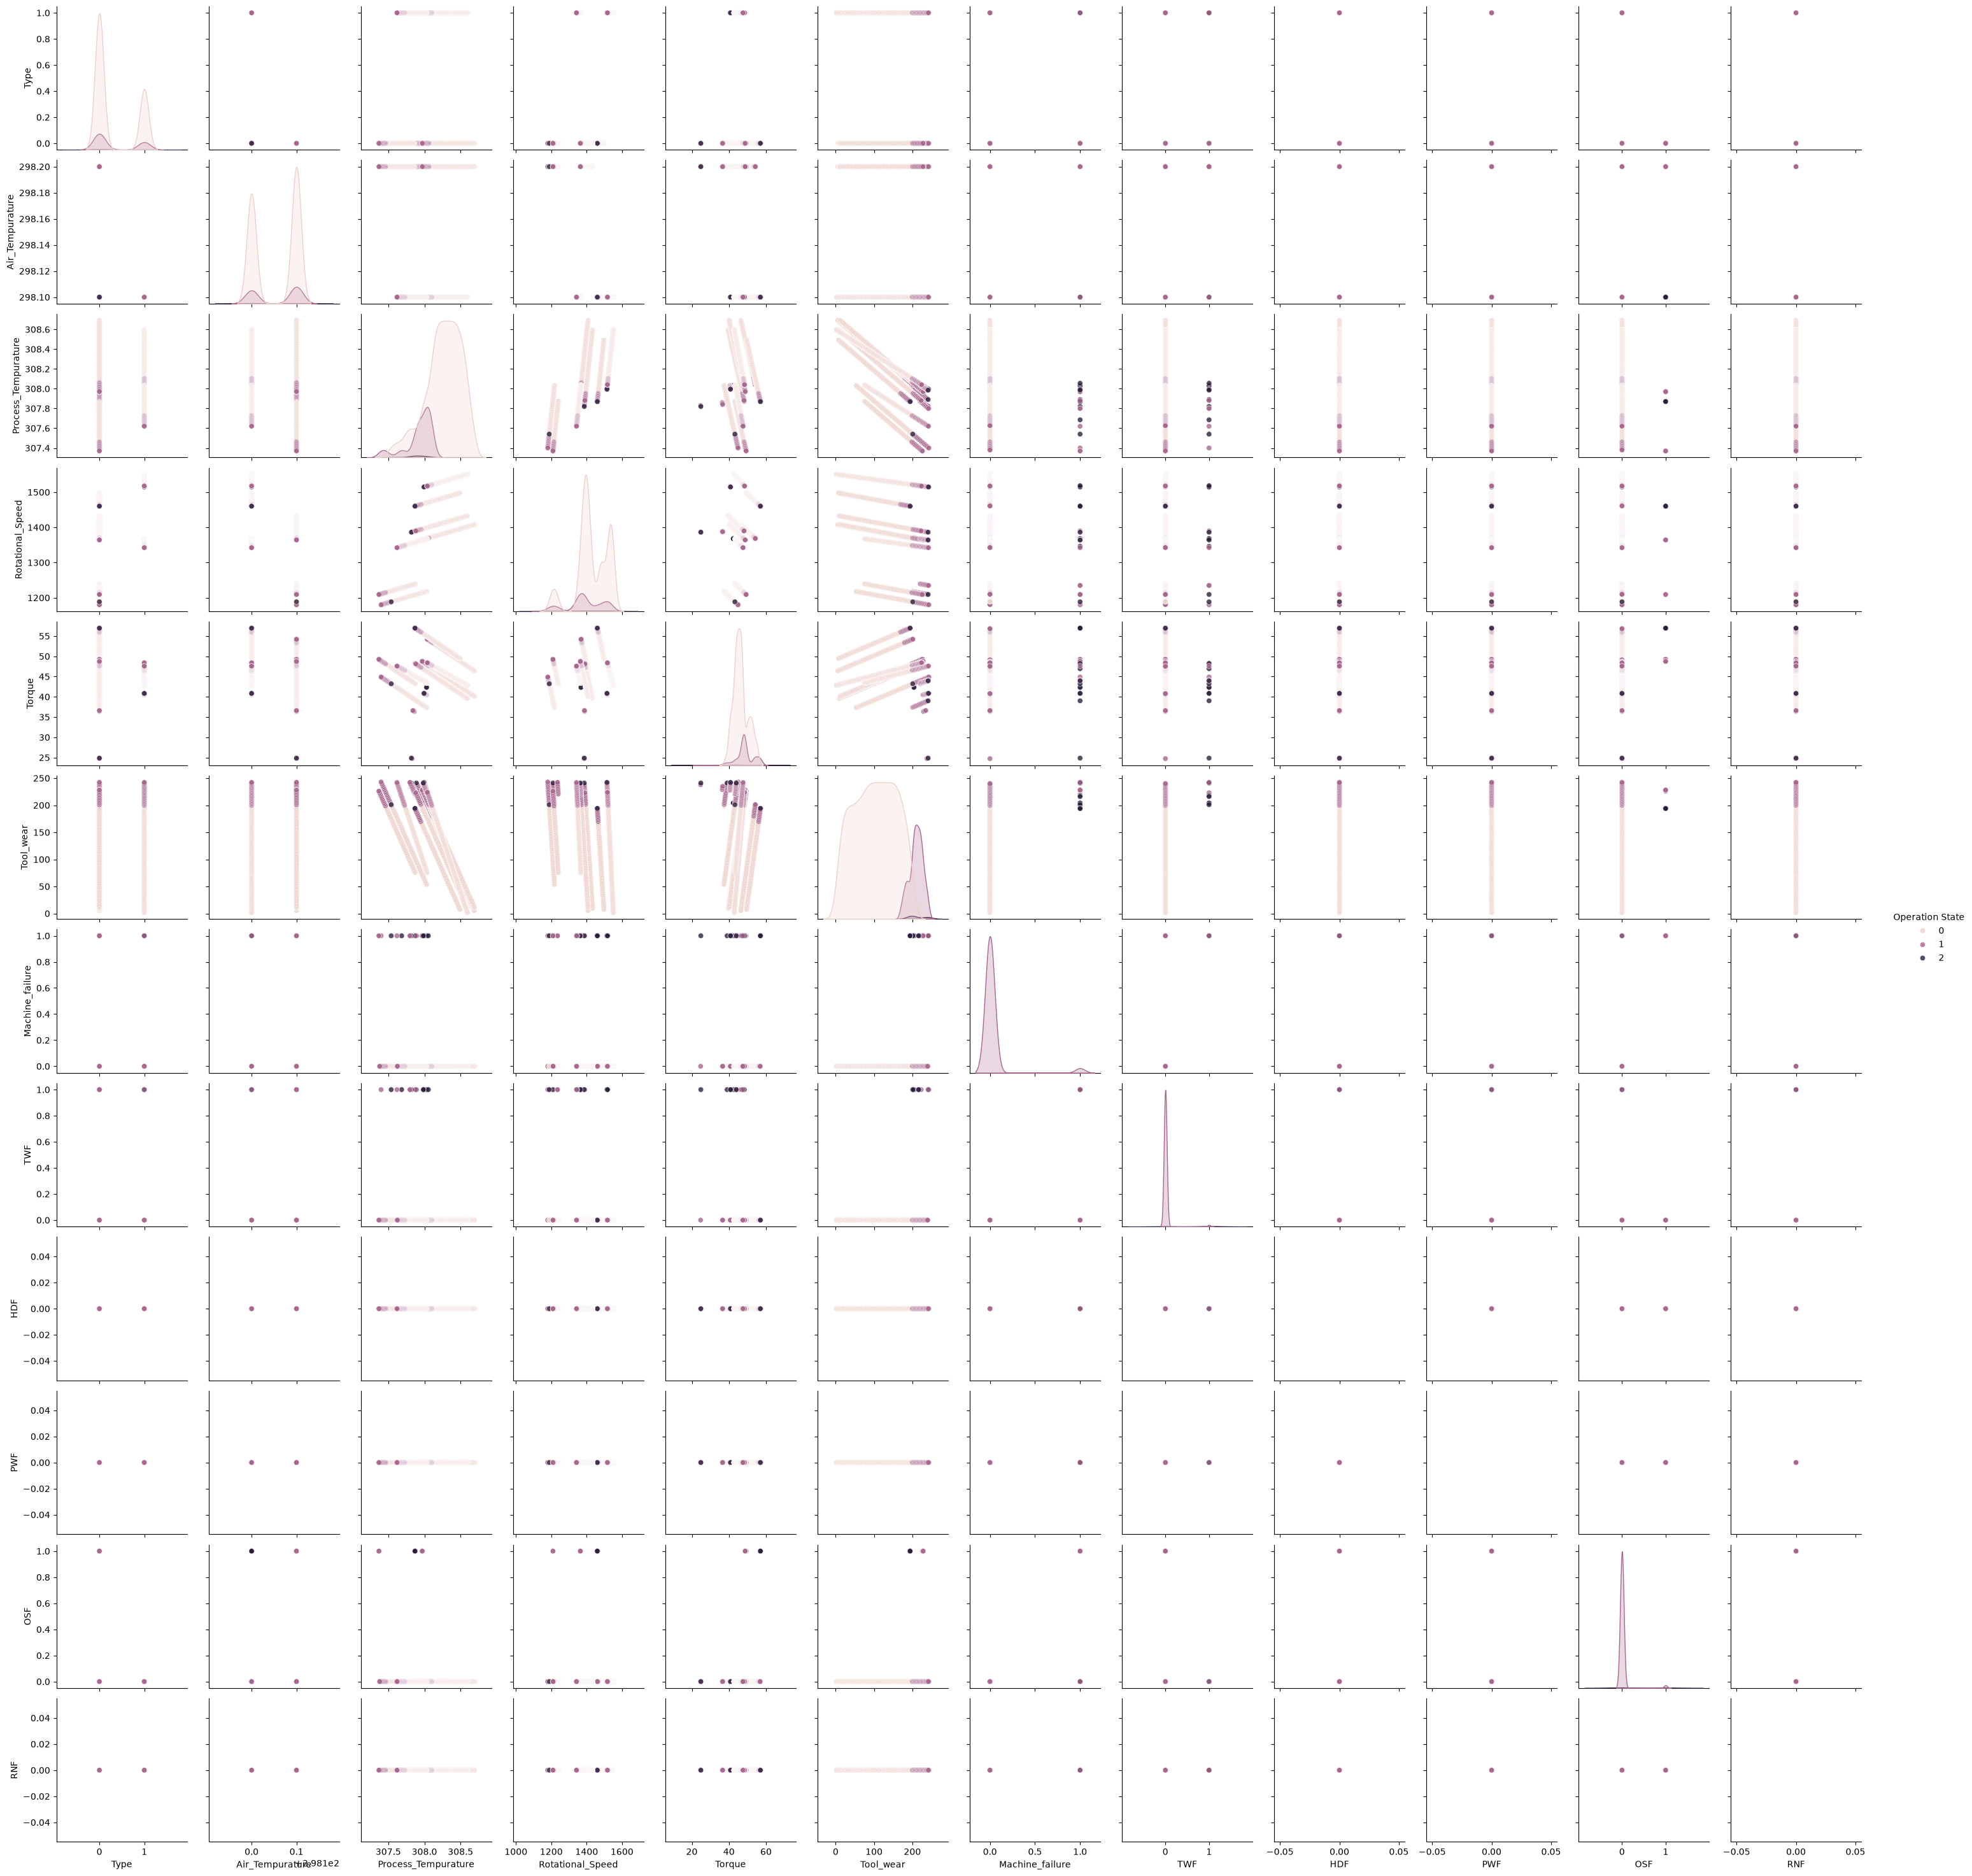

In [19]:
sns.pairplot(df, hue='Operation State', plot_kws={'alpha': 0.8})
plt.show()

In [20]:
cols = df.select_dtypes(include=['float64', 'int64']).columns

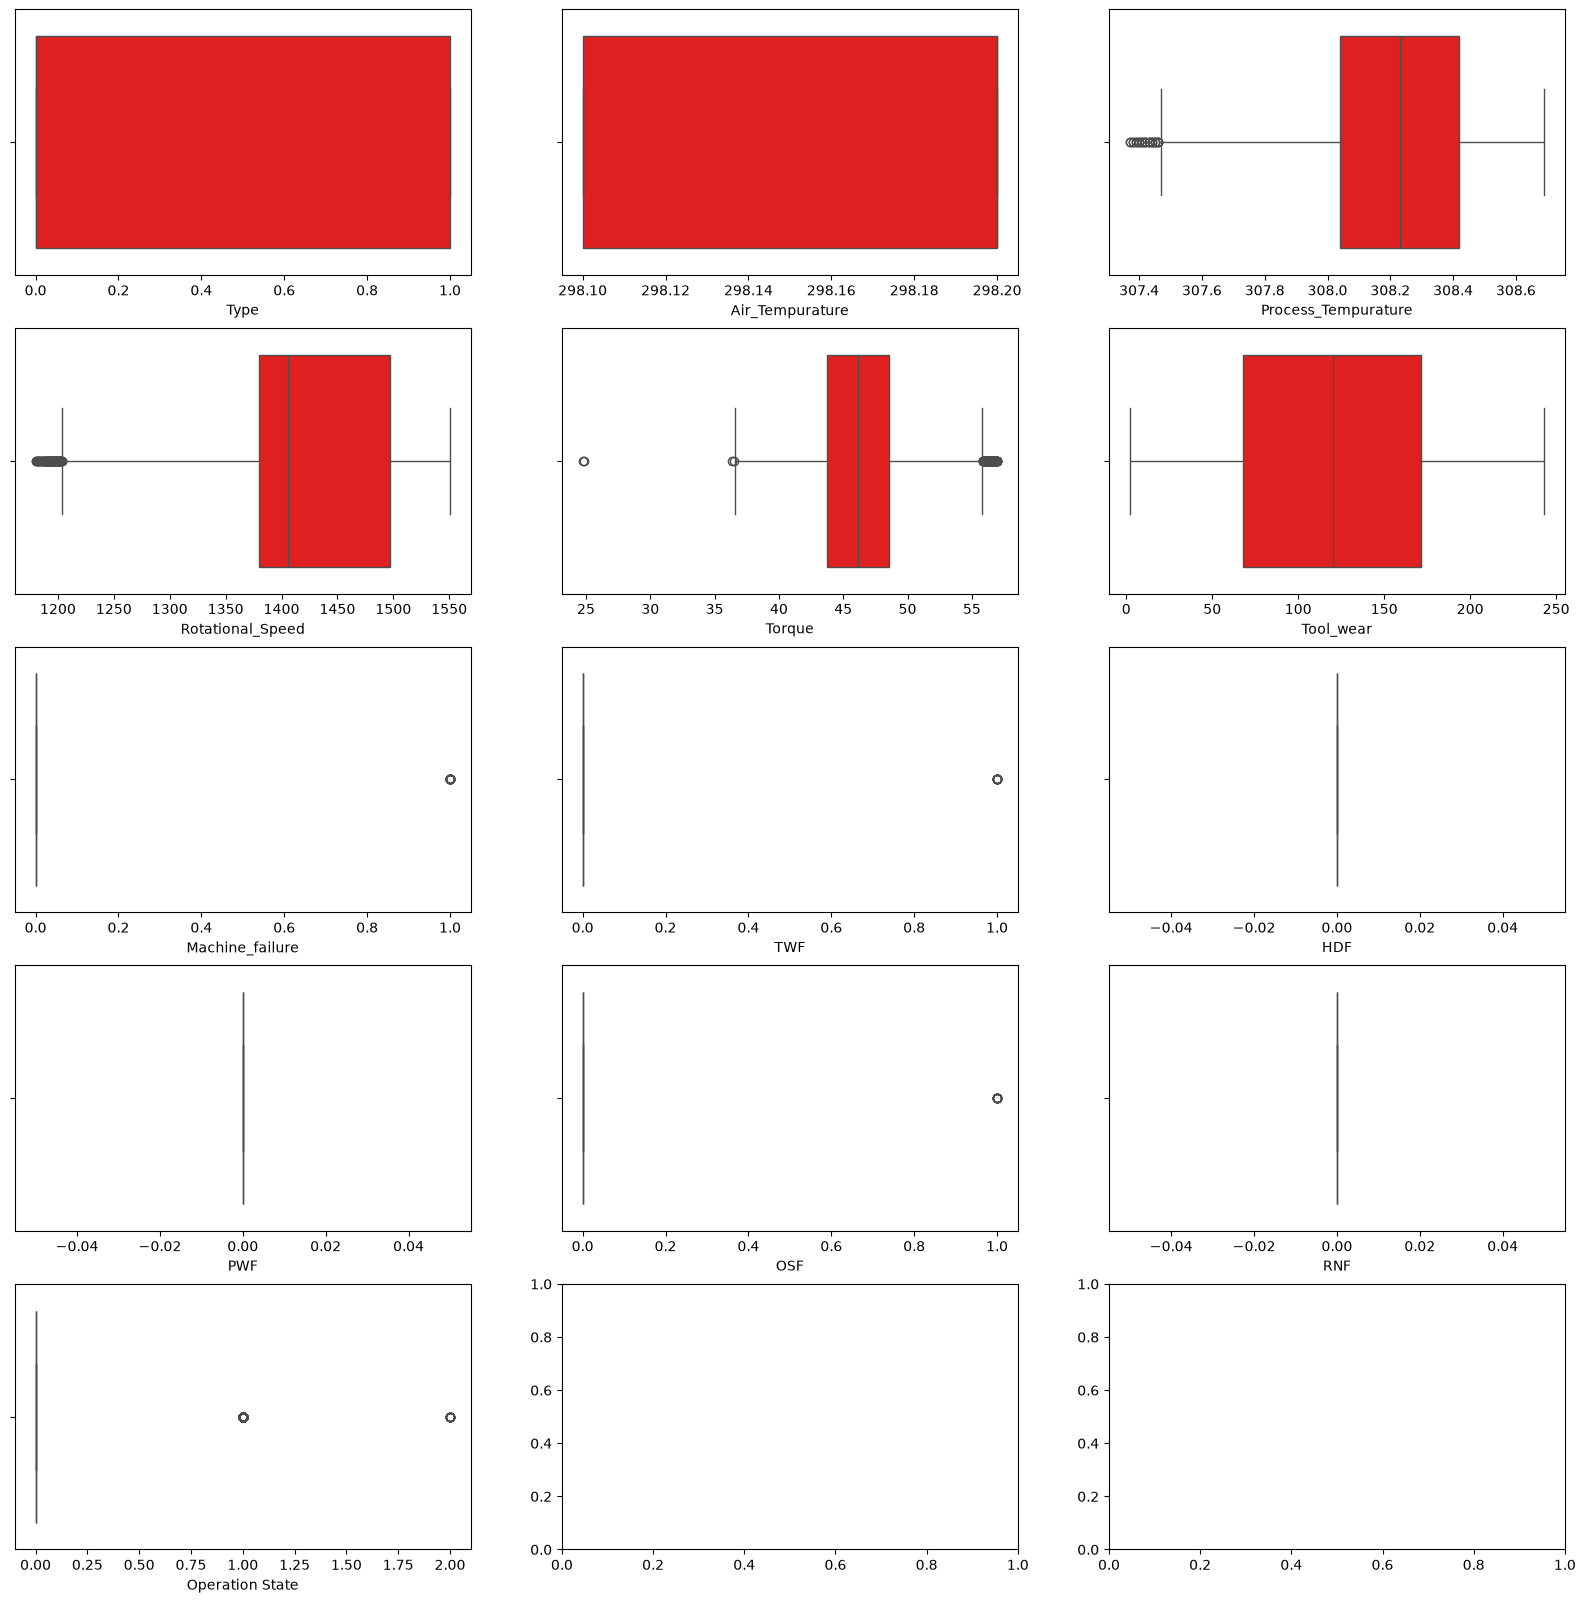

In [23]:
fig, axes = plt.subplots(5, 3, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.boxplot(x=df[col], color='red', ax=axes[i])

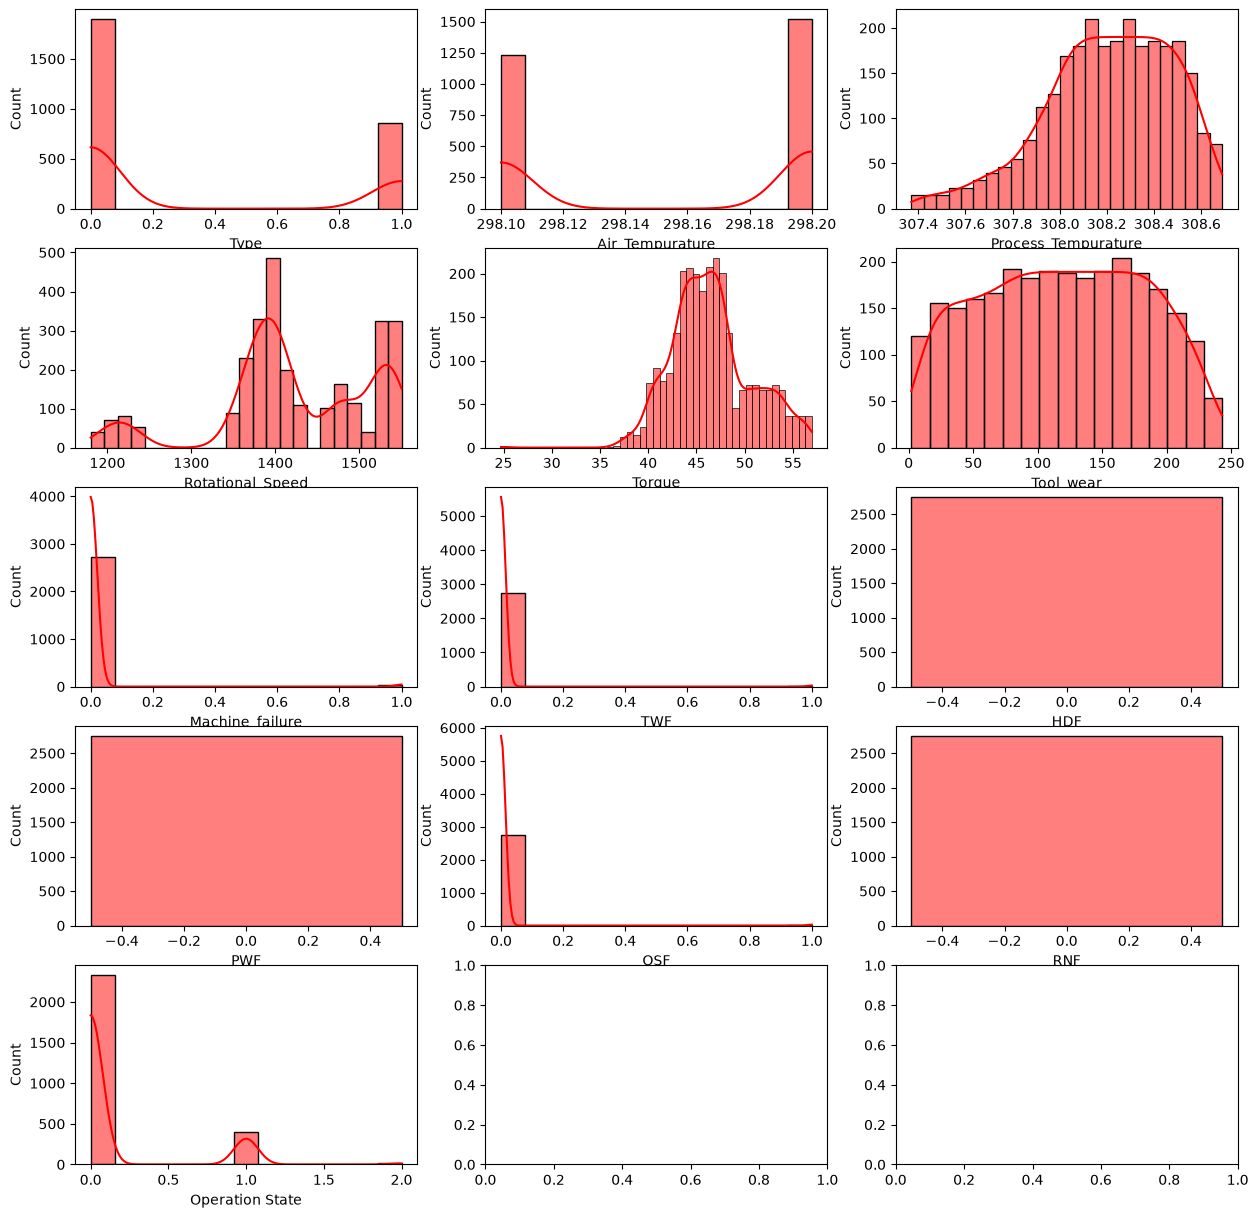

In [22]:
fig, axes = plt.subplots(5, 3, figsize=(15, 15))
axes = axes.flatten()
for i, col in enumerate(cols):
    sns.histplot(data=df[col], kde=True, color='red', ax=axes[i])

<Axes: >

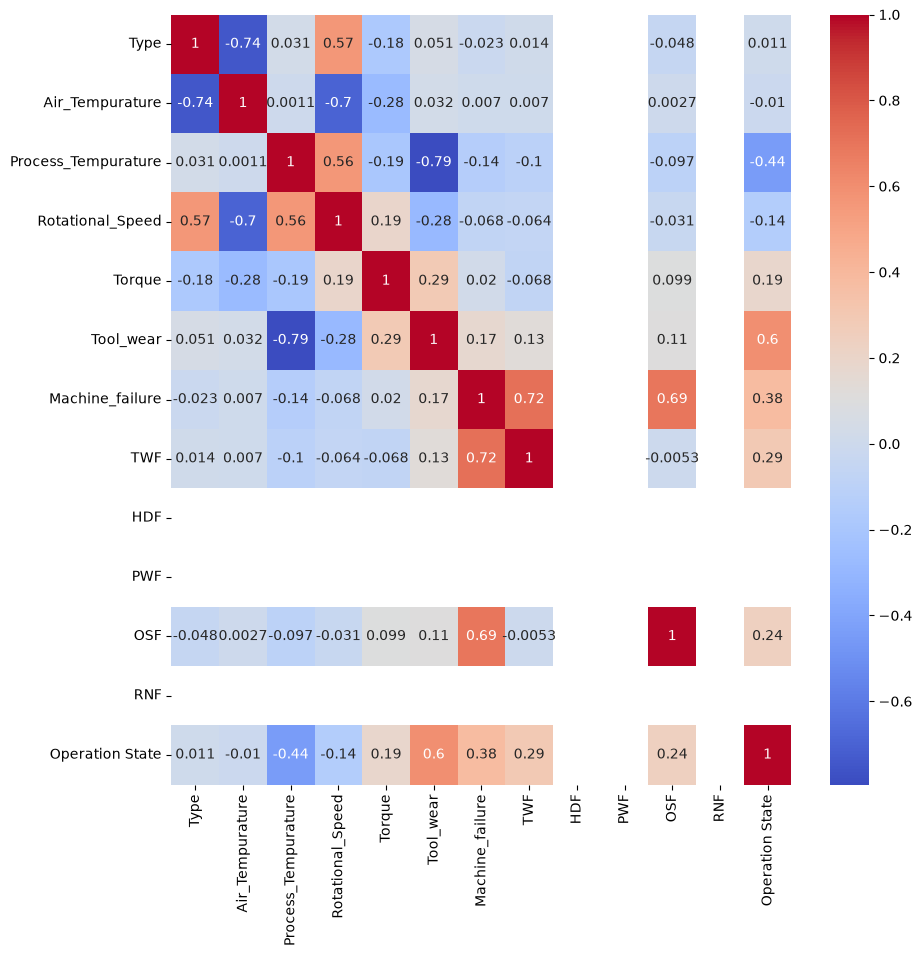

In [11]:
corr_matrix = df.corr()
plt.figure(figsize=(10,10))
sns.heatmap(data=corr_matrix, annot=True, cmap='coolwarm')

### Scale Data

In [9]:
cols = ["Air_Tempurature", "Process_Tempurature", "Rotational_Speed", "Torque", "Tool_wear"]
X = df[cols]
y = df["Operation State"]

In [10]:
X_min= np.min(X, axis=0)
X_max = np.max(X, axis=0)
denom = np.where(X_max - X_min == 0, 1.0, X_max - X_min)
X_scaled = (X - X_min) / denom

### Slip Data

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

### Train Data

In [13]:
from clazz.SoftmaxRegression import SoftmaxRegression

In [14]:
softmax = SoftmaxRegression()

In [15]:
softmax.fit(X=X_train, y=y_train, C=3)

### Predict Data

In [16]:
y_predict = softmax.predict(X_train)

In [17]:
y_test_predict = softmax.predict(X_test)

### Measure Performance

In [18]:
from sklearn.metrics import classification_report

In [19]:

print(classification_report(y_train, y_predict))
print(classification_report(y_test, y_test_predict))

              precision    recall  f1-score   support

           0       1.00      0.66      0.80      1858
           1       0.34      0.57      0.42       329
           2       0.02      0.64      0.04        14

    accuracy                           0.65      2201
   macro avg       0.45      0.62      0.42      2201
weighted avg       0.90      0.65      0.74      2201

              precision    recall  f1-score   support

           0       1.00      0.67      0.80       475
           1       0.31      0.51      0.39        74
           2       0.02      1.00      0.04         2

    accuracy                           0.65       551
   macro avg       0.44      0.73      0.41       551
weighted avg       0.90      0.65      0.74       551



In [20]:
print("y_test:", np.unique(y_train, return_counts=True))
print("y_pred:", np.unique(y_predict, return_counts=True))

y_test: (array([0, 1, 2]), array([1858,  329,   14]))
y_pred: (array([0, 1, 2]), array([1230,  551,  420]))


In [21]:
print("y_test:", np.unique(y_test, return_counts=True))
print("y_pred:", np.unique(y_test_predict, return_counts=True))

y_test: (array([0, 1, 2]), array([475,  74,   2]))
y_pred: (array([0, 1, 2]), array([318, 122, 111]))
